In [2]:
import warnings
warnings.filter676t5r-666666
]0'
'
iwarnings('ignore')
warnings.filterwarnings('ignore', category=FutureWarning)
ь
import os
import numpy as np 
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from IPython.display import clear_output

from tensorflow import keras
from IPython.display import clear_output
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import random

import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from keras import Sequential
from keras.layers import GlobalAveragePooling2D, Dropout, Dense, BatchNormalization, Conv2D, MaxPooling2D
from keras.callbacks import EarlyStopping, ModelCheckpoint

from keras.callbacks import EarlyStopping, ModelCheckpoint

In [3]:
rootPath = r'C:/Users/User/Desktop/mydata/train'
class_names = sorted(os.listdir(rootPath))[-6:]
class_names

['Good',
 'Hazardous',
 'Moderate',
 'Sencitive groups',
 'Unhealthy',
 'Very unhealthy']

In [4]:
sizes = [len(os.listdir(rootPath +'/'+ name)) for name in class_names]
sizes

[325, 6, 93, 655, 957, 270]

In [5]:
fig = px.pie(
    names=class_names,
    values=sizes,
    width=450,
    title='Класс түрлері',
    hole=0.4
)
fig.update_layout({'title':{'x':0.45}})
fig.show()

In [6]:
def load_random_img(dir, label):
    plt.figure(figsize=(10,10))
    i=0
    for label in class_names:
        i+=1
        plt.subplot(1, 6, i)
        file = random.choice(os.listdir(f'{dir}/{label}'))
        image_path = os.path.join(f'{dir}/{label}', file)
        img=cv2.imread(image_path)
        plt.title(label)
        plt.imshow(img)
        plt.grid(None)
        plt.axis('off')

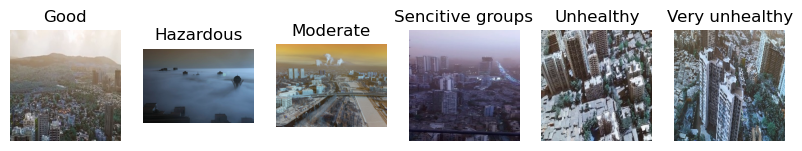

In [7]:
for i in range(1):
    load_random_img(rootPath, class_names)

In [8]:
pip install split-folders

  Obtaining dependency information for split-folders from https://files.pythonhosted.org/packages/b6/d5/307d63c03356bad6e141d8718d3f4116f51bd9c4b09e2614ffcee1f3c6fd/split_folders-0.5.1-py3-none-any.whl.metadata
Using cached split_folders-0.5.1-py3-none-any.whl (8.4 kB)
Note: you may need to restart the kernel to use updated packages.


In [15]:
import splitfolders
splitfolders.ratio(rootPath, output='rice_imgs', seed=123, ratio=(.7,.15,.15), group_prefix=None)

Copying files: 2306 files [00:05, 388.69 files/s]


In [16]:
batch_size = 128
img_height, img_width = 256, 256
input_shape = (img_height, img_width, 3)

Found 2306 images belonging to 6 classes.


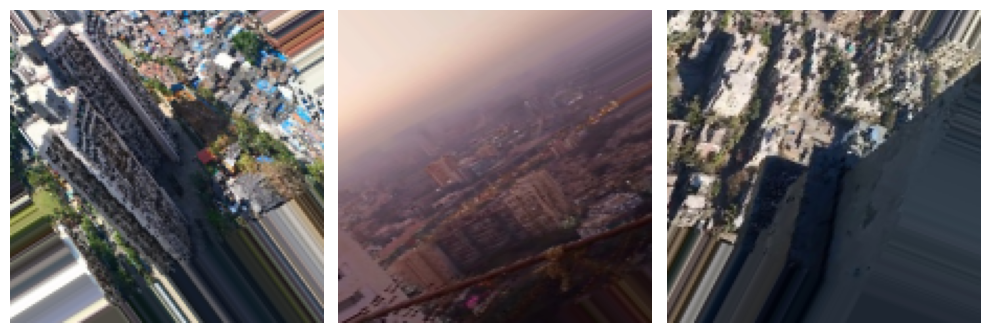

In [17]:
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

generator = datagen.flow_from_directory(
    rootPath,  
    target_size=(150, 150),  
    batch_size=32,
    class_mode='binary'  
)

augmented_images = generator[0]  
plt.figure(figsize=(10, 10))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(augmented_images[0][i])  
    plt.axis('off')
plt.tight_layout()
plt.show()

In [18]:
Train = datagen.flow_from_directory(
    'C:/Users/User/Desktop/mydata/train',
    target_size = (img_height, img_width),
    batch_size = batch_size,
    subset = "training",
    class_mode='categorical')

Val = datagen.flow_from_directory(
    'C:/Users/User/Desktop/mydata/val',
    target_size = (img_height, img_width),
    batch_size = batch_size,
    class_mode='categorical',
    shuffle=False)

Test = datagen.flow_from_directory(
    'C:/Users/User/Desktop/mydata/test',
    target_size = (img_height, img_width),
    batch_size = batch_size,
    class_mode='categorical',
    shuffle=False)

Found 2306 images belonging to 6 classes.
Found 37 images belonging to 6 classes.
Found 36 images belonging to 6 classes.


In [20]:
import tensorflow as tf


CNN = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=(img_height, img_width, 3)),
    tf.keras.layers.MaxPooling2D(pool_size=2, strides=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation='relu'),
    tf.keras.layers.Dense(units=num_classes, activation='softmax')
])

CNN.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = CNN.fit(
    Train,
    epochs=epochs,
    validation_data=Val
)


test_loss, test_accuracy = CNN.evaluate(Test)

print(f'Test Loss: {test_loss}')
print(f'Test Accuracy: {test_accuracy}')


Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 164s 6s/step - accuracy: 0.2606 - loss: 34.2493 - val_accuracy: 0.1081 - val_loss: 4.3365
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 116s 5s/step - accuracy: 0.3000 - loss: 1.8494 - val_accuracy: 0.1081 - val_loss: 1.9745
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 114s 5s/step - accuracy: 0.4262 - loss: 1.4825 - val_accuracy: 0.2703 - val_loss: 2.5208
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 115s 5s/step - accuracy: 0.4879 - loss: 1.2227 - val_accuracy: 0.2162 - val_loss: 3.0518
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 11782s 653s/step - accuracy: 0.5602 - loss: 1.0641 - val_accuracy: 0.2162 - val_loss: 3.2621
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - accuracy: 0.5848 - loss: 0.9932 - val_accuracy: 0.2703 - val_loss: 3.3864
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 79s 4s/step - accuracy: 0.5035 - loss: 1.0661 - val_accuracy: 0.1622 - val_loss: 3.5443
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - accuracy: 0.5439 - loss: 1.0608 - val_accuracy: 0.2432 -

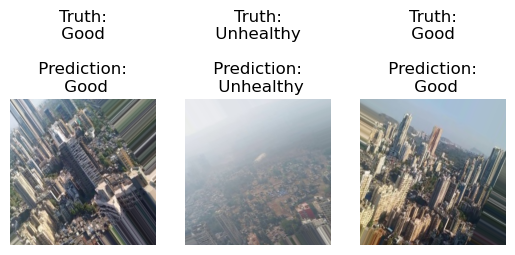

In [25]:
x, label= Train.__next__()
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x[i])
    result = np.where(label[i]==1)
    predict = CNN(tf.expand_dims(x[i], 0))
    score = tf.nn.softmax(predict[0])
    score_label = class_names[np.argmax(score)]
    plt.title(f'Truth:\n {class_names[result[0][0]]} \n\n Prediction: \n {score_label}')
    plt.axis(False) 

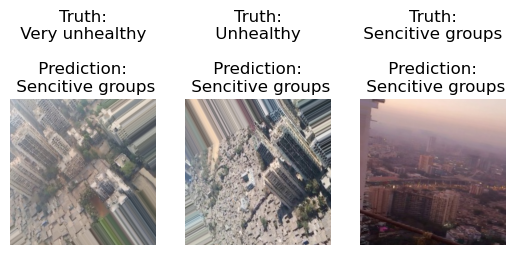

In [36]:
x, label= Train.__next__()  
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x[i])
    result = np.where(label[i]==1)
    predict = CNN(tf.expand_dims(x[i], 0))
    score = tf.nn.softmax(predict[0])
    score_label = class_names[np.argmax(score)]
    plt.title(f'Truth:\n {class_names[result[0][0]]} \n\n Prediction: \n {score_label}')
    plt.axis(False) 

In [1]:
pip install nbconvert[webpdf]

  Obtaining dependency information for pyppeteer<1.1,>=1 from https://files.pythonhosted.org/packages/10/46/33c0a9e7d37bf33487074de4399963462093043ad224d1881e41cbd937f3/pyppeteer-1.0.2-py3-none-any.whl.metadata
  Obtaining dependency information for pyee<9.0.0,>=8.1.0 from https://files.pythonhosted.org/packages/56/37/29d137df23ed1d88d8dcee8a6b8e789d1162042f194b5ccd0a48f503429b/pyee-8.2.2-py2.py3-none-any.whl.metadata
  Obtaining dependency information for urllib3<2.0.0,>=1.25.8 from https://files.pythonhosted.org/packages/33/cf/8435d5a7159e2a9c83a95896ed596f68cf798005fe107cc655b5c5c14704/urllib3-1.26.20-py2.py3-none-any.whl.metadata
     ---------------------------------------- 0.0/50.1 kB ? eta -:--:--
     ----------------------- -------------- 30.7/50.1 kB 435.7 kB/s eta 0:00:01
     ----------------------- -------------- 30.7/50.1 kB 435.7 kB/s eta 0:00:01
     ----------------------- -------------- 30.7/50.1 kB 435.7 kB/s eta 0:00:01
     ------------------------------- ------ 41

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spektral 1.3.1 requires tensorflow>=2.2.0; platform_machine != "arm64" or platform_system != "Darwin", which is not installed.
gradio 4.44.1 requires urllib3~=2.0, but you have urllib3 1.26.20 which is incompatible.
selenium 4.38.0 requires urllib3[socks]<3.0,>=2.5.0, but you have urllib3 1.26.20 which is incompatible.
tensorflow-intel 2.16.1 requires ml-dtypes~=0.3.1, but you have ml-dtypes 0.2.0 which is incompatible.


In [2]:
pip install --upgrade jupyter nbconvert


  Obtaining dependency information for jupyter from https://files.pythonhosted.org/packages/38/64/285f20a31679bf547b75602702f7800e74dbabae36ef324f716c02804753/jupyter-1.1.1-py2.py3-none-any.whl.metadata
  Obtaining dependency information for nbconvert from https://files.pythonhosted.org/packages/cc/9a/cd673b2f773a12c992f41309ef81b99da1690426bd2f96957a7ade0d3ed7/nbconvert-7.16.6-py3-none-any.whl.metadata
  Obtaining dependency information for mistune<4,>=2.0.3 from https://files.pythonhosted.org/packages/9b/f7/4a5e785ec9fbd65146a27b6b70b6cdc161a66f2024e4b04ac06a67f5578b/mistune-3.2.0-py3-none-any.whl.metadata
  Obtaining dependency information for fqdn from https://files.pythonhosted.org/packages/cf/58/8acf1b3e91c58313ce5cb67df61001fc9dcd21be4fadb76c1a2d540e09ed/fqdn-1.5.1-py3-none-any.whl.metadata
  Obtaining dependency information for isoduration from https://files.pythonhosted.org/packages/7b/55/e5326141505c5d5e34c5e0935d2908a74e4561eca44108fbfb9c13d2911a/isoduration-20.11.0-py3-none